# Step 7: Year-on-year change, 2023/24 to 2024/25

The TSMs started in 2023/24, so there are now two years of results. Everything so far has compared different landlords in one year, but with two years I can compare the same landlords with themselves, and ask some new questions:

1. **How did the sector change**, and on which measures?
2. **Regression to the mean:** landlords with unusually low scores tend to improve the next year just by chance. How strong is that effect?
3. **Change against change:** did landlords whose repairs or complaints **got better** also see satisfaction **go up**? Comparing each landlord with itself takes out everything that stays the same about it (region, stock, tenant profile, local reputation), which gets closer to cause and effect than notebook 3 could.

**Data:** the RSH TSM full data sets for both years. RSH names them by the year they were published, which is easy to mix up:
- `2024_TSM_Full_Data_v2.1_FINAL.xlsx` covers **2023/24** (April 2023 to March 2024)
- `2025_TSM_Full_Data_v1.1_FINAL.xlsx` covers **2024/25** (April 2024 to March 2025), the file I used in notebooks 1 to 6

## 1. Load both years

In Colab, I upload **both TSM files at once**.

In [1]:
import re
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import os

try:
    from google.colab import files
    uploaded = files.upload()
    # The 2023/24 file starts "2024_" and the 2024/25 file starts "2025_".
    path_2324 = next(name for name in uploaded if name.startswith("2024_TSM"))
    path_2425 = next(name for name in uploaded if name.startswith("2025_TSM"))
except ImportError:
    path_2324 = "../data/2024_TSM_Full_Data_v2.1_FINAL.xlsx"
    path_2425 = "../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx"

The two files are laid out slightly differently: the header row is in a different place, the 2023/24 sheets have some blank rows at the bottom, councils are labelled "LARP" instead of "LA", and "Face to Face" is written "FacetoFace". So rather than writing two separate bits of loading code, I wrote **one function** that copes with both. That way, if something needs fixing, I only have to fix it in one place.

In [2]:
# RSH's codes for values that aren't real numbers. This year I also need [S], which means suppressed.
missing_codes = ["[X]", "[Z]", "[E]", "[U]", "[S]"]


# Rather than hard-coding the header row, this finds it: the row whose first cell says "Landlord name".
def read_sheet(path, sheet):
    """Read a TSM sheet whose header row is the one starting 'Landlord name'."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    header_row = raw.index[raw.iloc[:, 0].astype(str).str.strip() == "Landlord name"][0]
    table = pd.read_excel(path, sheet_name=sheet, header=header_row, na_values=missing_codes)
    # Get rid of the blank rows at the bottom (rows with no landlord code).
    return table.dropna(subset=["Landlord code"])


# My column-finding function from notebooks 2 to 6.
def find_col(df, must_contain, starts_with=None):
    hits = [col for col in df.columns if all(t in col for t in must_contain)
            and (starts_with is None or col.startswith(starts_with))]
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}"
    return hits[0]


# The pattern for the 12 survey measures (from notebook 1).
tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"

# The operational measures. I had to write the start texts so they match both years' column names.
measures = {
    "repairs_on_time_pc": (["(RP02 1)"], "Proportion"),
    "non_decent_pc": (["(RP01)"], "Proportion"),
    "complaints_s1_per_1000": (["(CH01 1)"], "LCRA - Number of stage one"),
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA - Proportion"),
    "complaints_s2_per_1000": (["(CH01 2)"], "LCRA - Number of stage two"),
}


# Load one year into a tidy table, one row per landlord.
def load_year(path, year):
    """Survey measures and operational measures for one TSM year (year = '24' or '25')."""
    perception = read_sheet(path, f"TSM{year}_LCRA_Perception")
    # The management sheet's name is slightly different each year, so I find it by how it starts.
    mi_sheet = next(s for s in pd.ExcelFile(path).sheet_names if s.startswith(f"TSM{year}_Management"))
    management = read_sheet(path, mi_sheet)

    # The context columns, with .replace() making the labels the same in both years.
    tidy = pd.DataFrame({
        "code": perception["Landlord code"].astype(str),
        "landlord": perception["Landlord name"],
        "type": perception["Landlord type"].replace({"LARP": "LA"}),
        "size_band": perception[find_col(perception, ["group size"])],
        "region": perception["Landlord predominant region"],
        "method": perception["Predominant collection method"].replace({"FacetoFace": "Face to Face"}),
        "n": perception["Total sample size achieved"],
    })
    # The 12 survey measures, renamed to their codes.
    for col in perception.columns:
        match = re.match(tp_pattern, col)
        if match:
            tidy[match.group(1)] = pd.to_numeric(perception[col], errors="coerce")

    # The operational measures, as numbers.
    ops = pd.DataFrame({"code": management["Landlord code"].astype(str)})
    for short, (texts, start) in measures.items():
        ops[short] = pd.to_numeric(management[find_col(management, texts, start)], errors="coerce")

    return tidy.merge(ops, on="code", how="left", validate="one_to_one")


# Now loading each year is just one line.
y2324 = load_year(path_2324, "24")
y2425 = load_year(path_2425, "25")
print("2023/24:", y2324.shape, "  2024/25:", y2425.shape)

2023/24: (355, 24)   2024/25: (353, 24)


## 2. Match housing associations across the two years

In [3]:
ha_2324 = y2324[y2324["type"] == "PRP"]
ha_2425 = y2425[y2425["type"] == "PRP"]

# Who's only in one of the years? (Mergers, new registrations, or landlords dropping below 1,000 homes.)
print("Only in 2023/24:", ha_2324.loc[~ha_2324["code"].isin(ha_2425["code"]), "landlord"].tolist())
print("Only in 2024/25:", ha_2425.loc[~ha_2425["code"].isin(ha_2324["code"]), "landlord"].tolist())

# Put the two years side by side. suffixes adds "_24" or "_25" to the column names,
# so TP01 becomes TP01_24 and TP01_25.
both = ha_2324.merge(ha_2425, on="code", suffixes=("_24", "_25"), validate="one_to_one")
print("In both years:", len(both))

tp_cols = [f"TP{i:02d}" for i in range(1, 13)]
op_cols = list(measures)

# The change in every measure (2024/25 minus 2023/24), in new columns starting "chg_".
for col in tp_cols + op_cols:
    both["chg_" + col] = both[col + "_25"] - both[col + "_24"]

# Changing survey method can move scores on its own, so I flagged the landlords that did.
both["method_changed"] = (both["method_24"] != both["method_25"]).astype(int)
print("Changed main survey method:", both["method_changed"].sum())

Only in 2023/24: ['Longhurst Group Limited', 'Shepherds Bush Housing Association Limited', 'Silva Homes Limited', 'Thames Valley Housing Association Limited', 'The Wrekin Housing Group Limited']
Only in 2024/25: ['Metropolitan Housing Trust Limited', 'Sage Homes RP Limited', "Durham Aged Mineworkers' Homes Association"]
In both years: 192
Changed main survey method: 34


192 housing associations are in both years, and 34 of them changed their main survey method, which I'll need to allow for.

## 3. How did the sector change?

In [4]:
# A summary of the changes in the 12 survey measures (in percentage points).
both[["chg_" + col for col in tp_cols]].describe().T[["count", "mean", "50%", "min", "max"]].round(1)

,count,mean,50%,min,max
chg_TP01,192.0,1.2,1.3,-11.4,17.6
chg_TP02,192.0,1.4,1.2,-10.6,15.2
chg_TP03,192.0,1.6,1.4,-10.6,26.4
chg_TP04,192.0,1.5,1.4,-13.0,16.2
chg_TP05,192.0,1.2,0.5,-12.5,16.0
chg_TP06,192.0,1.8,1.5,-14.4,17.8
chg_TP07,192.0,2.2,1.8,-13.3,20.9
chg_TP08,192.0,1.6,1.2,-18.0,19.1
chg_TP09,191.0,2.0,2.1,-23.4,25.6
chg_TP10,191.0,2.7,1.9,-10.9,44.5


Satisfaction went up slightly on every measure across the sector, with a median rise of about 1 to 2 points.

In [5]:
# How stable are scores from one year to the next? Near 1 means high scorers stayed high.
print(f"Correlation of overall satisfaction between years: {both['TP01_24'].corr(both['TP01_25']):.2f}")
print(f"Correlation of repairs on time between years:      {both['repairs_on_time_pc_24'].corr(both['repairs_on_time_pc_25']):.2f}")
print(f"Correlation of stage 2 complaints between years:   {both['complaints_s2_per_1000_24'].corr(both['complaints_s2_per_1000_25']):.2f}")

# And how the operational measures changed across the sector.
both[["chg_" + col for col in op_cols]].describe().T[["count", "mean", "50%"]].round(1)

Correlation of overall satisfaction between years: 0.91
Correlation of repairs on time between years:      0.76
Correlation of stage 2 complaints between years:   0.73


,count,mean,50%
chg_repairs_on_time_pc,190.0,1.2,0.9
chg_non_decent_pc,191.0,-0.4,0.0
chg_complaints_s1_per_1000,191.0,11.4,8.2
chg_complaints_s1_on_time_pc,191.0,6.1,3.3
chg_complaints_s2_per_1000,191.0,4.0,3.1


**Satisfaction is very stable** (correlation 0.91), so a landlord's score one year is a strong guide to the next. The operational measures are a bit less stable.

**Complaint volumes went up a lot across the sector**: a median rise of about 8 stage 1 and 3 stage 2 complaints per 1,000 homes. The Housing Ombudsman's Complaint Handling Code became **statutory on 1 April 2024**, the first day of the 2024/25 year. So part of the rise is probably landlords recording more contacts as formal complaints, not just worse service. I need to keep that in mind whenever I look at complaint changes.

## 4. Which measures improved most?

In [6]:
# For each survey measure: the sector median in each year, the median change,
# and the share of landlords whose score went up.
sector_change = pd.DataFrame({
    "median 2023/24": [both[col + "_24"].median() for col in tp_cols],
    "median 2024/25": [both[col + "_25"].median() for col in tp_cols],
    "median change": [both["chg_" + col].median() for col in tp_cols],
    "% of landlords improving": [(both["chg_" + col] > 0).mean() * 100 for col in tp_cols],
}, index=tp_cols)
sector_change.round(1)

,median 2023/24,median 2024/25,median change,% of landlords improving
TP01,74.2,75.4,1.3,65.6
TP02,73.4,76.1,1.2,63.0
TP03,69.6,70.8,1.4,63.5
TP04,73.1,74.8,1.4,65.1
TP05,79.5,80.3,0.5,58.9
TP06,63.4,65.6,1.5,67.2
TP07,73.0,74.2,1.8,70.8
TP08,79.5,80.4,1.2,69.8
TP09,37.2,38.7,2.1,66.1
TP10,67.0,68.7,1.9,63.5


**Every measure went up at the median**, by between 0.5 points (feeling safe) and 2.1 points (complaints handling). Around two thirds of landlords improved on each measure, most often on keeping tenants informed (71%). Complaints handling started lowest (37.2%) and rose most, though it's still far below everything else.

## 5. Regression to the mean

This was a new idea to me. When a score is partly luck, an unusually low score tends to be followed by a higher one, just because the luck evens out. It's called **regression to the mean**, and it can make struggling landlords look like they've improved when nothing has actually changed.

I can measure it by regressing each landlord's **change** on its **starting score**. A negative slope means low starters tend to go up and high starters tend to go down.

In [7]:
# A simple regression: change in overall satisfaction explained by the 2023/24 score.
rtm = smf.ols("chg_TP01 ~ TP01_24", data=both).fit()
print(f"Slope: {rtm.params['TP01_24']:.3f} (each point higher at the start goes with "
      f"{abs(rtm.params['TP01_24']):.2f} points less improvement)")

# What that means for landlords starting from different places.
for start in [60, 70, 80, 90]:
    expected = rtm.params["Intercept"] + rtm.params["TP01_24"] * start
    print(f"Expected change for a landlord starting at {start}%: {expected:+.1f} points")

Slope: -0.137 (each point higher at the start goes with 0.14 points less improvement)
Expected change for a landlord starting at 60%: +2.9 points
Expected change for a landlord starting at 70%: +1.6 points
Expected change for a landlord starting at 80%: +0.2 points
Expected change for a landlord starting at 90%: -1.2 points


Landlords that started low usually improved. One starting at 60% would be expected to go up by about 3 points, while one at 90% would be expected to slip back by about 1, even if nothing about its service had changed. So a low scorer improving isn't automatically proof that its changes worked, and a high scorer dipping isn't automatically bad news. Anyone comparing TSMs year on year needs to allow for this.

## 6. Change against change

Now the question I most wanted to answer: across the sector, did **changes** in operational performance go with **changes** in satisfaction?

This is called a **first-difference** model: I regress the change in TP01 on the changes in the operational measures. Anything about a landlord that **didn't change** between the years (region, type of stock, tenant profile, local reputation) drops out, because it's the same in both years and cancels out when I subtract. That's a big advantage over the single-year model.

To check the result isn't a fluke of one set-up, I fitted four versions:
1. **Basic:** changes only
2. **Plus method change:** allowing for landlords that changed their main survey method
3. **Excluding method changers:** leaving those landlords out completely
4. **Plus starting score:** allowing for regression to the mean

In [8]:
# The changes in the four notebook 3 operational measures.
change_inputs = ["chg_complaints_s2_per_1000", "chg_repairs_on_time_pc",
                 "chg_complaints_s1_on_time_pc", "chg_non_decent_pc"]
fd_data = both.dropna(subset=["chg_TP01"] + change_inputs).copy()
# " + ".join turns the list into "a + b + c + d" for the formula.
inputs = " + ".join(change_inputs)

# The four versions, as {name: (formula, which landlords)}.
versions = {
    "1. Basic": (f"chg_TP01 ~ {inputs}", fd_data),
    "2. Plus method change": (f"chg_TP01 ~ {inputs} + method_changed", fd_data),
    "3. Excluding method changers": (f"chg_TP01 ~ {inputs}", fd_data[fd_data["method_changed"] == 0]),
    "4. Plus starting score": (f"chg_TP01 ~ {inputs} + method_changed + TP01_24", fd_data),
}

# Fit all four in one go (a dictionary comprehension).
fd_results = {name: smf.ols(formula, data=data).fit(cov_type="HC3") for name, (formula, data) in versions.items()}

# Pull each version's coefficients, p-values and R-squared into one table so I can compare them.
rows = {}
for name, result in fd_results.items():
    row = {}
    for col in change_inputs:
        row[col.replace("chg_", "") + " coef"] = result.params[col]
        row[col.replace("chg_", "") + " p"] = result.pvalues[col]
    row["R-squared"] = result.rsquared
    row["landlords"] = int(result.nobs)
    rows[name] = row
pd.DataFrame(rows).round(3)

,1. Basic,2. Plus method change,3. Excluding method changers,4. Plus starting score
complaints_s2_per_1000 coef,0.047,0.038,-0.079,-0.037
complaints_s2_per_1000 p,0.608,0.651,0.078,0.576
repairs_on_time_pc coef,0.065,0.073,0.058,0.079
repairs_on_time_pc p,0.069,0.041,0.052,0.014
complaints_s1_on_time_pc coef,-0.036,-0.036,-0.013,-0.044
complaints_s1_on_time_pc p,0.144,0.153,0.620,0.063
non_decent_pc coef,-0.044,-0.047,0.021,-0.063
non_decent_pc p,0.967,0.963,0.941,0.941
R-squared,0.042,0.067,0.055,0.189
landlords,190.000,190.000,156.000,190.000


**What the table tells me:**

- **Repairs on time** is positive in every version (about +0.06 to +0.08 points of satisfaction per extra point of repairs on time), and at or near significance (p between 0.01 and 0.07). Landlords that got quicker at repairs tended to see satisfaction go up.
- **Stage 2 complaints** has no consistent link: the sign flips between versions and it's never clearly different from zero. Either the recording change under the statutory Code is hiding a real effect, or the link in the single-year model is about stable differences between landlords rather than something that changes year to year.
- **Complaints answered on time** and **non-decent homes** show no clear link.
- **R-squared is low** (0.04 to 0.19). Over one year, changes in these measures explain very little of the change in satisfaction. Most of the year-to-year movement is something else, including sampling noise.

### Comparing with the single-year model

Next I put the change model's coefficients beside the single-year model (notebook 3's model, fitted on 2024/25 for the same landlords). If an operational measure really does drive satisfaction, I'd expect both to point the same way.

In [9]:
# Rebuild the notebook 3 single-year model using the 2024/25 columns, with the same groupings.
cross = both.copy()
cross["method_group"] = pd.Categorical(
    cross["method_25"].where(cross["method_25"].isin(["Telephone", "Internet", "Postal"]), "Other"),
    ["Telephone", "Internet", "Postal", "Other"])
cross["size_band"] = pd.Categorical(cross["size_band_25"], ["5,000-40,000", "<5,000", ">40,000"])
cross["region"] = pd.Categorical(cross["region_25"], ["South", "North", "Midlands", "London", "Mixed"])
level_inputs = [col.replace("chg_", "") + "_25" for col in change_inputs]
cross = cross.dropna(subset=["TP01_25"] + level_inputs)
single_year = smf.ols(f"TP01_25 ~ {' + '.join(level_inputs)} + C(method_group) + C(size_band) + C(region)",
                      data=cross).fit(cov_type="HC3")

# I compare against version 2 of the change model (allowing for method changes).
change_model = fd_results["2. Plus method change"]

# Side by side with 95% confidence intervals. Both are in the same units
# (points of satisfaction per unit of the measure), so they can be compared directly.
compare = pd.DataFrame({
    "single-year coef": single_year.params[level_inputs].values,
    "single-year CI low": single_year.conf_int().loc[level_inputs, 0].values,
    "single-year CI high": single_year.conf_int().loc[level_inputs, 1].values,
    "change coef": change_model.params[change_inputs].values,
    "change CI low": change_model.conf_int().loc[change_inputs, 0].values,
    "change CI high": change_model.conf_int().loc[change_inputs, 1].values,
}, index=[col.replace("chg_", "") for col in change_inputs])
compare.round(3)

,single-year coef,single-year CI low,single-year CI high,change coef,change CI low,change CI high
complaints_s2_per_1000,-0.493,-0.609,-0.376,0.038,-0.128,0.205
repairs_on_time_pc,0.169,0.077,0.262,0.073,0.003,0.143
complaints_s1_on_time_pc,0.082,0.007,0.157,-0.036,-0.086,0.014
non_decent_pc,-1.532,-2.624,-0.441,-0.047,-2.029,1.935


**Repairs on time** points the same way in both models, but the effect within landlords is about half the size (0.07 against 0.17). **Stage 2 complaints** has a clear negative link between landlords but none within landlords over one year.

I read that two things pull change-model estimates towards zero, so this doesn't mean the single-year model was wrong:
- **Measurement noise:** a one-year change contains the error from *both* years, which waters down any real link (this is called **attenuation**).
- **Lags:** satisfaction might take more than a year to catch up with better service.

## 7. Charts

In [10]:
# My house style from notebook 4 (notebook 4 explains each setting).
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, HIGHLIGHT, ACCENT, CONTEXT = "#e1e0d9", "#c3c2b7", "#2a78d6", "#eb6834", "#c3c2b7"
SOURCE = "Sources: RSH Tenant Satisfaction Measures 2023/24 and 2024/25"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_2, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
})


def titles(fig, title, subtitle):
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, SOURCE, ha="left", va="bottom", fontsize=8, color=MUTED)


os.makedirs("charts", exist_ok=True)

# Plain English labels for the 12 measures (as in notebook 4).
labels = {
    "TP01": "Overall service", "TP02": "Repairs service", "TP03": "Time taken for repair",
    "TP04": "Home well maintained", "TP05": "Home is safe", "TP06": "Listens and acts",
    "TP07": "Keeps tenants informed", "TP08": "Fair and respectful", "TP09": "Complaints handling",
    "TP10": "Communal areas", "TP11": "Positive neighbourhood role", "TP12": "Handling of ASB",
}

### Chart 10: How the sector changed on each measure

The median change across the 192 housing associations on each survey measure, with the share of landlords that improved written alongside.

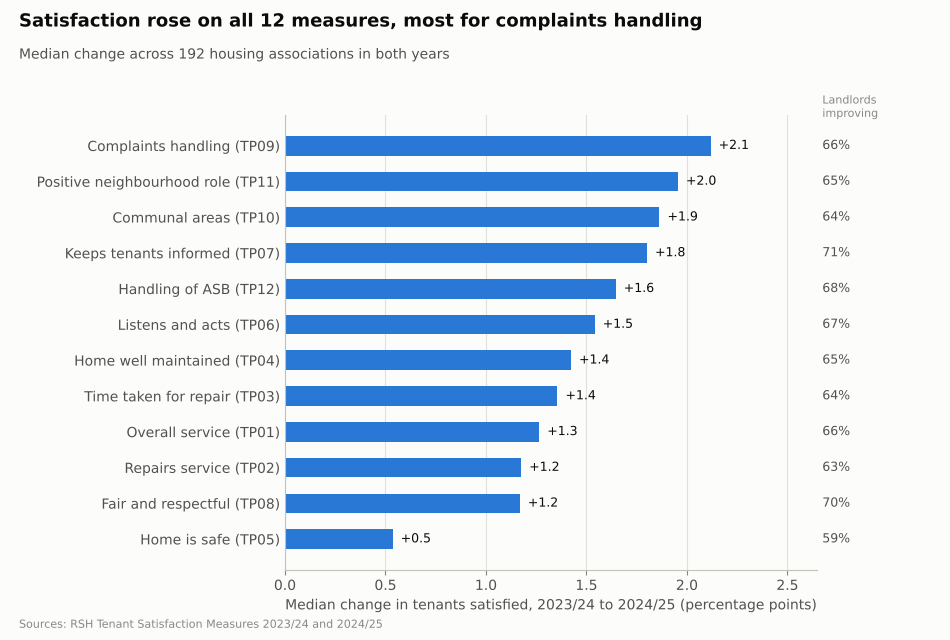

In [11]:
# Sort by median change, smallest first, so the biggest rise ends up at the top.
order = sector_change.sort_values("median change").index
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(9.5, 6.4))
fig.subplots_adjust(left=0.30, right=0.86, top=0.82, bottom=0.11)

# One bar per measure, all in one colour, with the median change written at the end.
ax.barh(y, sector_change.loc[order, "median change"], height=0.55, color=HIGHLIGHT)
for yi, col in zip(y, order):
    ax.text(sector_change.loc[col, "median change"] + 0.04, yi, f"{sector_change.loc[col, 'median change']:+.1f}",
            va="center", ha="left", fontsize=9, color=INK)
    # The share of landlords improving, down the right-hand side.
    ax.text(1.01, yi, f"{sector_change.loc[col, '% of landlords improving']:.0f}%", transform=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=9, color=INK_2)
ax.text(1.01, len(order) - 0.3, "Landlords\nimproving", transform=ax.get_yaxis_transform(),
        va="bottom", ha="left", fontsize=8, color=MUTED)

ax.set_yticks(y, [f"{labels[col]} ({col})" for col in order])
ax.set_xlim(0, sector_change["median change"].max() * 1.25)
ax.set_xlabel("Median change in tenants satisfied, 2023/24 to 2024/25 (percentage points)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

top = order[-1]
titles(fig, f"Satisfaction rose on all 12 measures, most for {labels[top].lower()}",
       f"Median change across {len(both)} housing associations in both years")
fig.savefig("charts/10_sector_change.png", dpi=200)
plt.show()

### Chart 11: Regression to the mean

Starting score against change for every housing association, with the regression line from section 5.

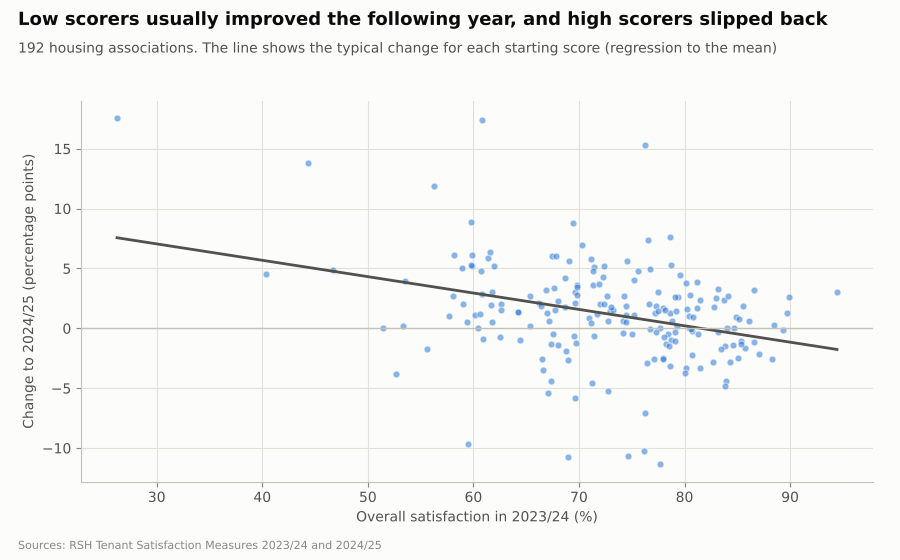

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.6))
fig.subplots_adjust(left=0.09, right=0.97, top=0.82, bottom=0.14)

# Every housing association as a dot, plus the regression line and a line at zero change.
ax.scatter(both["TP01_24"], both["chg_TP01"], s=24, color=HIGHLIGHT, alpha=0.55, edgecolors=SURFACE, linewidths=0.8)
xs = np.linspace(both["TP01_24"].min(), both["TP01_24"].max(), 50)
ax.plot(xs, rtm.params["Intercept"] + rtm.params["TP01_24"] * xs, color=INK_2, linewidth=2)
ax.axhline(0, color=BASELINE, linewidth=1)

ax.set_xlabel("Overall satisfaction in 2023/24 (%)")
ax.set_ylabel("Change to 2024/25 (percentage points)")

titles(fig, "Low scorers usually improved the following year, and high scorers slipped back",
       f"{len(both)} housing associations. The line shows the typical change for each starting score "
       "(regression to the mean)")
fig.savefig("charts/11_regression_to_mean.png", dpi=200)
plt.show()

### Chart 12: Single-year link against change link

Two estimates for each operational measure, in the same units: the **single-year** model (differences between landlords in 2024/25) and the **change** model (changes within each landlord). The whiskers are 95% confidence intervals.

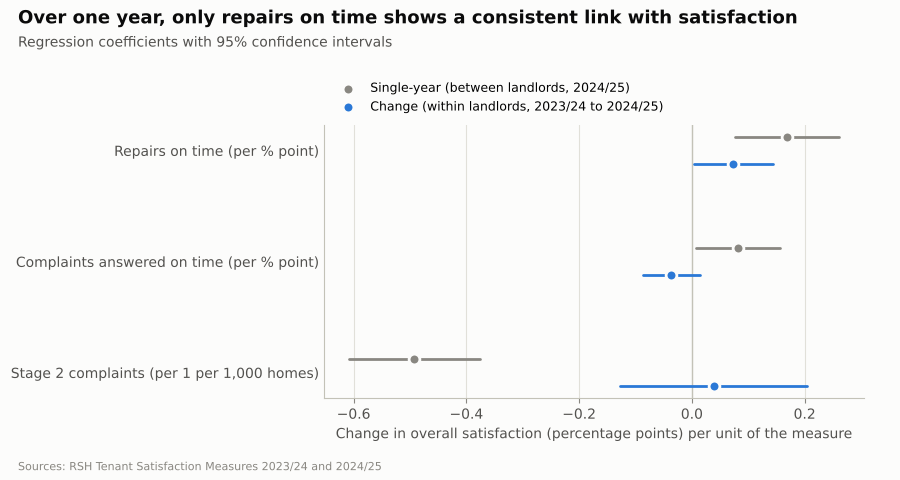

In [13]:
# Plain English labels, top to bottom.
plain = {
    "repairs_on_time_pc": "Repairs on time (per % point)",
    "complaints_s1_on_time_pc": "Complaints answered on time (per % point)",
    "complaints_s2_per_1000": "Stage 2 complaints (per 1 per 1,000 homes)",
}
# I left non-decent homes out: its values are so tiny that its coefficient is huge and squashes everything else.
rows = list(plain)
y = np.arange(len(rows))[::-1]

fig, ax = plt.subplots(figsize=(9, 4.8))
fig.subplots_adjust(left=0.36, right=0.96, top=0.74, bottom=0.17)

ax.axvline(0, color=BASELINE, linewidth=1)
# Two estimates per row, nudged up and down a little so they don't sit on top of each other.
for offset, prefix, colour, label in [(0.12, "single-year", MUTED, "Single-year (between landlords, 2024/25)"),
                                       (-0.12, "change", HIGHLIGHT, "Change (within landlords, 2023/24 to 2024/25)")]:
    ax.hlines(y + offset, compare.loc[rows, f"{prefix} CI low"], compare.loc[rows, f"{prefix} CI high"],
              color=colour, linewidth=2, capstyle="round")
    ax.scatter(compare.loc[rows, f"{prefix} coef"], y + offset, s=60, color=colour, edgecolors=SURFACE,
               linewidths=2, zorder=3, label=label)

ax.set_yticks(y, [plain[r] for r in rows])
ax.set_xlabel("Change in overall satisfaction (percentage points) per unit of the measure")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=1, frameon=False, fontsize=9)

titles(fig, "Over one year, only repairs on time shows a consistent link with satisfaction",
       "Regression coefficients with 95% confidence intervals")
fig.savefig("charts/12_single_year_vs_change.png", dpi=200)
plt.show()

## What I found

- **Satisfaction is very stable year to year** (correlation 0.91), and went up slightly across the sector on all 12 measures (median +1.3 points for overall satisfaction).
- **Regression to the mean is real and sizeable.** Each extra point at the start goes with 0.14 points less improvement, so a landlord at 60% would be expected to rise about 3 points and one at 90% to fall about 1, with no change in service.
- **Comparing landlords with themselves, only repairs on time has a consistent link with satisfaction**: getting better at it goes with a small rise in satisfaction (about +0.07 points per point), in the same direction as the single-year model but about half the size.
- **Changes in complaint volumes show no consistent link**, possibly because the statutory Complaint Handling Code (from April 2024) changed what landlords record.

**Limitations:**
- **Only two years.** One year-on-year change is noisy; a third year (2025/26) would make the change model much more reliable.
- **Attenuation:** noise in both years waters down the change-model estimates, so the real effects might be bigger than they look here.
- **Complaints recording changed** with the statutory Code, so complaint figures might not be comparable across the two years.
- **Survey methods changed** for 34 of the 192 housing associations. Versions 2 and 3 of the model allow for this, and the conclusions hold.

**Next:** notebook 8 tries machine learning, to see whether it can do better than my regression.